# 사진 2장으로 스테레오 거리 측정 (Colab)

왼쪽/오른쪽 카메라로 찍은 사진 2장을 올리면 **시차(disparity) 맵과 거리 맵**을 계산합니다.

**사용법**: 위에서부터 셀을 순서대로 실행하세요 (`Shift + Enter`).

| 단계 | 내용 |
|---|---|
| 0 | 준비 (라이브러리, 한글 폰트) |
| 1 | 설정값 입력 (카메라 간격, 화각) |
| C1~C3 | **(선택)** 체커보드 사진으로 캘리브레이션 → `stereo_calib.npz` 생성 |
| 2 | 왼쪽 사진, 오른쪽 사진 업로드 |
| 3~5 | 정렬 → 시차 계산 → 거리 계산 (자동) |
| 6 | 결과 보기 (마우스를 올리면 거리 표시) |
| 7 | 원하는 지점 거리 측정 |

캘리브레이션을 하지 않을 거면 C1~C3 셀은 건너뛰세요.

**촬영 팁**
- 두 사진은 **같은 카메라 높이, 같은 방향**으로, 옆으로만 평행 이동해서 찍기 (예: 6cm 간격)
- **왼쪽 = 피사체를 바라볼 때 왼쪽 카메라**
- 움직이는 물체 X, 무늬 없는 벽 X, 밝은 곳 O

**정확도**
- 캘리브레이션(C1~C3 셀 또는 PC의 `python stereo.py calibrate`)을 하면 → **정확한 측정**
- 없으면 → 화각(FOV)으로 초점거리를 추정하는 **근사 측정** (오차 10~30% 가능)

In [1]:
#@title 0. 준비 (라이브러리, 한글 폰트)
import os, re, glob, shutil, zipfile, subprocess
import cv2, numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from google.colab import files

# 그래프 한글 깨짐 방지 (나눔고딕 설치)
FONT = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
if not os.path.exists(FONT):
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)
if os.path.exists(FONT):
    font_manager.fontManager.addfont(FONT)
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

CALIB_RESULT = None   # C2 셀에서 캘리브레이션하면 파일 경로가 저장됨
print("준비 완료, OpenCV", cv2.__version__)

준비 완료, OpenCV 4.14.0


In [2]:
#@title 1. 설정 { display-mode: "form" }
BASELINE_MM = 50.0     #@param {type:"number"}
#@markdown ↑ 두 카메라(촬영 위치) 사이 거리(mm). 캘리브레이션 파일을 쓰면 무시됨
HFOV_DEG = 78.0        #@param {type:"number"}
#@markdown ↑ 카메라 가로 화각(도). ESP32-CAM(OV2640 기본 렌즈) ≈ 66, 스마트폰 기본 카메라 ≈ 65~75
RESIZE_WIDTH = 640     #@param {type:"integer"}
#@markdown ↑ 계산용 가로 해상도. 큰 사진은 줄여야 빠르고 잘 맞음 (0 = 원본 유지)
RECTIFY_MODE = "auto"  #@param ["auto", "y-align", "none"]
#@markdown ↑ auto: 캘리브레이션 파일이 있으면 사용, 없으면 y-align (특징점으로 세로 어긋남 보정)
BLOCK_SIZE = 5         #@param {type:"slider", min:3, max:15, step:2}
MAX_DIST_CM = 500      #@param {type:"integer"}
#@markdown ↑ 이보다 먼 값은 표시하지 않음
DISP_OFFSET_PX = 4.1  #@param {type:"number"}
#@markdown ↑ 시차 보정값(px). 카메라가 살짝 안쪽/바깥쪽을 향해 생기는 오차 보정. 실측 2지점으로 계산 (모르면 0)

---
## (선택) 캘리브레이션: 체커보드 사진으로 `stereo_calib.npz` 만들기

**준비**
- 체커보드 인쇄 (예: 10×7칸 → 내부 코너 9×6), 평평한 판에 붙이기. 한 칸 크기를 자로 정확히 재기
- 측정에 쓸 **같은 두 카메라, 같은 고정 상태**로 체커보드를 여러 위치·각도로 **20~30쌍** 촬영
- 한 쌍 = 같은 순간의 왼쪽 사진 + 오른쪽 사진. 체커보드 전체가 두 사진 모두에 보여야 함

**업로드 방법 (둘 중 하나)**
- **A. zip 파일**: PC의 `python stereo.py collect`로 만든 `calib` 폴더를 압축 (`L_00.png`, `R_00.png` …). 이름에 `left`/`right`가 들어간 파일도 인식
- **B. 사진 직접 선택**: 왼쪽 사진들을 한꺼번에 선택 → 이어서 오른쪽 사진들을 한꺼번에 선택. **파일 이름 순서로 짝을 지으므로** 촬영 순서가 같아야 함

⚠ 캘리브레이션 후 카메라 간격·각도가 바뀌면 다시 해야 합니다.

In [ ]:
#@title C1. 캘리브레이션 사진 업로드 { display-mode: "form" }
BOARD_COLS = 9      #@param {type:"integer"}
BOARD_ROWS = 6      #@param {type:"integer"}
#@markdown ↑ 체커보드 **내부 코너** 개수 (10×7칸 보드 → 9, 6)
SQUARE_MM = 25.0    #@param {type:"number"}
#@markdown ↑ 체커보드 한 칸의 실제 크기(mm)
CALIB_WIDTH = 640   #@param {type:"integer"}
#@markdown ↑ 캘리브레이션 해상도(가로). 측정 사진도 자동으로 이 크기로 맞춤. ESP32-CAM VGA면 640 (0 = 원본)

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

def natural_key(p):
    # IMG_2 < IMG_10 순서로 정렬
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", os.path.basename(p))]

def side_of(p):
    n = os.path.basename(p).lower()
    if n.startswith("l_") or "left" in n: return "L"
    if n.startswith("r_") or "right" in n: return "R"
    return None

shutil.rmtree("calib_imgs", ignore_errors=True)
os.makedirs("calib_imgs", exist_ok=True)

print("zip 파일이 있으면 zip을, 없으면 '왼쪽 사진들'을 모두 선택하세요")
up = files.upload()
zips = [k for k in up if k.lower().endswith(".zip")]
if zips:
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall("calib_imgs")
    imgs = [p for p in glob.glob("calib_imgs/**/*", recursive=True) if p.lower().endswith(IMG_EXT)]
    rights = {}
    for p in imgs:
        if side_of(p) == "R":
            key = re.sub(r"(?i)^r_|right", "#", os.path.basename(p), count=1)
            rights[key] = p
    calib_pairs = []
    for p in sorted(imgs, key=natural_key):
        if side_of(p) == "L":
            key = re.sub(r"(?i)^l_|left", "#", os.path.basename(p), count=1)
            if key in rights:
                calib_pairs.append((p, rights[key]))
else:
    lefts = sorted([k for k in up if k.lower().endswith(IMG_EXT)], key=natural_key)
    print(f"왼쪽 {len(lefts)}장 업로드됨. 이제 '오른쪽 사진들'을 모두 선택하세요")
    up_r = files.upload()
    rights = sorted([k for k in up_r if k.lower().endswith(IMG_EXT)], key=natural_key)
    if len(lefts) != len(rights):
        raise SystemExit(f"왼쪽 {len(lefts)}장, 오른쪽 {len(rights)}장으로 개수가 다릅니다. 다시 실행하세요.")
    calib_pairs = list(zip(lefts, rights))

print(f"\n짝지어진 사진: {len(calib_pairs)}쌍")
for l, r in calib_pairs[:5]:
    print(f"  {os.path.basename(l)}  ↔  {os.path.basename(r)}")
if len(calib_pairs) > 5:
    print("  ...")
if len(calib_pairs) < 10:
    print("⚠ 10쌍 이상 필요합니다 (권장 20~30쌍)")

In [ ]:
#@title C2. 캘리브레이션 실행
BOARD = (BOARD_COLS, BOARD_ROWS)
objp = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_MM
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-5)

def load_calib_img(p):
    img = cv2.imread(p, cv2.IMREAD_COLOR)
    if img is not None and CALIB_WIDTH and img.shape[1] != CALIB_WIDTH:
        s = CALIB_WIDTH / img.shape[1]
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img

def find_corners(gray):
    # 1차: 정확도가 높은 SB 알고리즘, 실패하면 2차: 기존 알고리즘 + 서브픽셀 보정
    ok, c = cv2.findChessboardCornersSB(gray, BOARD, cv2.CALIB_CB_NORMALIZE_IMAGE | cv2.CALIB_CB_EXHAUSTIVE)
    if not ok:
        ok, c = cv2.findChessboardCorners(gray, BOARD, cv2.CALIB_CB_ADAPTIVE_THRESH | cv2.CALIB_CB_NORMALIZE_IMAGE)
        if ok:
            c = cv2.cornerSubPix(gray, c, (11, 11), (-1, -1), crit)
    if ok:
        c = c.reshape(-1, 1, 2).astype(np.float32)   # 알고리즘마다 배열 모양이 달라서 통일
    return ok, c

obj_pts, pts_l, pts_r, used, previews = [], [], [], [], []
img_size = None
for pl_path, pr_path in calib_pairs:
    a, b = load_calib_img(pl_path), load_calib_img(pr_path)
    if a is None or b is None or a.shape != b.shape:
        print(f"✖ {os.path.basename(pl_path)}: 읽기 실패 또는 좌우 크기 다름"); continue
    if img_size is None:
        img_size = (a.shape[1], a.shape[0])
    elif (a.shape[1], a.shape[0]) != img_size:
        print(f"✖ {os.path.basename(pl_path)}: 다른 사진과 해상도가 다름"); continue
    ga, gb = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY), cv2.cvtColor(b, cv2.COLOR_BGR2GRAY)
    oka, ca = find_corners(ga)
    okb, cb = find_corners(gb)
    if not (oka and okb):
        print(f"✖ {os.path.basename(pl_path)}: 코너 인식 실패 (L:{oka} R:{okb})"); continue
    # 좌우에서 코너 번호 순서가 반대로 잡힌 경우 뒤집기
    if np.dot((ca[-1] - ca[0]).ravel(), (cb[-1] - cb[0]).ravel()) < 0:
        cb = cb[::-1].copy()
    obj_pts.append(objp); pts_l.append(ca); pts_r.append(cb)
    used.append(pl_path)
    if len(previews) < 3:
        va, vb = a.copy(), b.copy()
        cv2.drawChessboardCorners(va, BOARD, ca, True); cv2.drawChessboardCorners(vb, BOARD, cb, True)
        previews.append(np.hstack([va, vb]))

print(f"\n코너 인식 성공: {len(used)} / {len(calib_pairs)}쌍")
if len(used) < 8:
    raise SystemExit("인식된 쌍이 너무 적습니다. BOARD_COLS/ROWS(내부 코너 수)가 맞는지, 체커보드가 다 보이는지 확인하세요.")

def run_calibration(obj, l, r):
    eL, K1, D1, rvL, tvL = cv2.calibrateCamera(obj, l, img_size, None, None)
    eR, K2, D2, rvR, tvR = cv2.calibrateCamera(obj, r, img_size, None, None)
    rms, K1, D1, K2, D2, R, T, _, _ = cv2.stereoCalibrate(
        obj, l, r, K1, D1, K2, D2, img_size, criteria=crit, flags=cv2.CALIB_FIX_INTRINSIC)
    # 사진 쌍별 재투영 오차 (나쁜 사진 골라내기용)
    per = []
    for i in range(len(obj)):
        pa, _ = cv2.projectPoints(obj[i], rvL[i], tvL[i], K1, D1)
        pb, _ = cv2.projectPoints(obj[i], rvR[i], tvR[i], K2, D2)
        rms_l = np.sqrt(np.mean(np.sum((l[i].reshape(-1, 2) - pa.reshape(-1, 2)) ** 2, axis=1)))
        rms_r = np.sqrt(np.mean(np.sum((r[i].reshape(-1, 2) - pb.reshape(-1, 2)) ** 2, axis=1)))
        per.append(max(rms_l, rms_r))
    return dict(eL=eL, eR=eR, rms=rms, K1=K1, D1=D1, K2=K2, D2=D2, R=R, T=T, per=np.array(per))

res = run_calibration(obj_pts, pts_l, pts_r)

# 오차가 큰 사진(흔들림, 오인식)을 빼고 한 번 더
bad = res["per"] > max(1.0, 2.5 * np.median(res["per"]))
if bad.any() and (~bad).sum() >= 8:
    for i in np.where(bad)[0]:
        print(f"  제외: {os.path.basename(used[i])} (오차 {res['per'][i]:.2f}px)")
    keep = np.where(~bad)[0]
    obj_pts = [obj_pts[i] for i in keep]; pts_l = [pts_l[i] for i in keep]; pts_r = [pts_r[i] for i in keep]
    used = [used[i] for i in keep]
    res = run_calibration(obj_pts, pts_l, pts_r)

R1, R2, P1, P2, Qc, _, _ = cv2.stereoRectify(res["K1"], res["D1"], res["K2"], res["D2"],
                                             img_size, res["R"], res["T"], alpha=0)
CALIB_RESULT = "stereo_calib.npz"
np.savez(CALIB_RESULT, K1=res["K1"], D1=res["D1"], K2=res["K2"], D2=res["D2"],
         R1=R1, R2=R2, P1=P1, P2=P2, Q=Qc, size=np.array(img_size))

baseline = np.linalg.norm(res["T"])
hfov = np.degrees(2 * np.arctan(img_size[0] / 2 / res["K1"][0, 0]))
grade = "우수" if res["rms"] < 0.5 else ("보통" if res["rms"] < 1.0 else "나쁨 → 재촬영 권장")
print("\n===== 캘리브레이션 결과 =====")
print(f"사용한 사진 쌍     : {len(used)}")
print(f"해상도             : {img_size[0]} x {img_size[1]}")
print(f"단일 카메라 오차   : 왼쪽 {res['eL']:.3f}px / 오른쪽 {res['eR']:.3f}px")
print(f"스테레오 RMS 오차  : {res['rms']:.3f}px  ({grade})")
print(f"측정된 카메라 간격 : {baseline:.1f} mm   (1번 설정값 BASELINE_MM = {BASELINE_MM})")
print(f"초점거리 / 화각    : {res['K1'][0, 0]:.1f}px / 약 {hfov:.1f}°")
print(f"저장               : {CALIB_RESULT}\n")
if abs(baseline - BASELINE_MM) > 0.2 * BASELINE_MM:
    print("⚠ 측정된 카메라 간격이 실제와 20% 이상 다릅니다. SQUARE_MM 값이나 좌우 사진이 바뀌지 않았는지 확인하세요.")

for p in previews:
    plt.figure(figsize=(12, 4)); plt.imshow(cv2.cvtColor(p, cv2.COLOR_BGR2RGB))
    plt.title("코너 인식 예시 (왼쪽 | 오른쪽) — 색깔 선의 순서가 좌우 같아야 함"); plt.axis("off"); plt.show()

In [ ]:
#@title C3. 평행화 확인 + 파일 다운로드
DOWNLOAD_CALIB = True  #@param {type:"boolean"}
c = np.load(CALIB_RESULT)
sz = tuple(int(v) for v in c["size"])
m1 = cv2.initUndistortRectifyMap(c["K1"], c["D1"], c["R1"], c["P1"], sz, cv2.CV_32FC1)
m2 = cv2.initUndistortRectifyMap(c["K2"], c["D2"], c["R2"], c["P2"], sz, cv2.CV_32FC1)
a, b = load_calib_img(calib_pairs[0][0]), load_calib_img(calib_pairs[0][1])
pair = np.hstack([cv2.remap(a, *m1, cv2.INTER_LINEAR), cv2.remap(b, *m2, cv2.INTER_LINEAR)])
plt.figure(figsize=(14, 5)); plt.imshow(cv2.cvtColor(pair, cv2.COLOR_BGR2RGB))
for y in np.linspace(0, sz[1], 14)[1:-1]:
    plt.axhline(y, color="lime", lw=0.7)
plt.title("평행화 결과: 체커보드 코너가 좌우에서 같은 초록 가로줄 위에 있으면 성공"); plt.axis("off"); plt.show()
if DOWNLOAD_CALIB:
    files.download(CALIB_RESULT)   # PC의 stereo.py measure 에서도 그대로 사용 가능

In [3]:
#@title 2. 측정할 사진 업로드
def upload_one(msg):
    print(msg)
    up = files.upload()
    if not up:
        raise SystemExit("업로드가 취소되었습니다. 이 셀을 다시 실행하세요.")
    return list(up.keys())[0]

LEFT_PATH = upload_one("① 왼쪽 사진을 선택하세요")
RIGHT_PATH = upload_one("② 오른쪽 사진을 선택하세요")
if CALIB_RESULT and os.path.exists(CALIB_RESULT):
    CALIB_PATH = CALIB_RESULT
    print("③ 위(C2)에서 만든 캘리브레이션 파일을 사용합니다")
else:
    print("③ (선택) stereo_calib.npz 를 올리려면 선택, 없으면 '취소'를 누르세요")
    up = files.upload()
    CALIB_PATH = next((k for k in up if k.endswith(".npz")), None)

print(f"\n왼쪽: {LEFT_PATH}\n오른쪽: {RIGHT_PATH}\n캘리브레이션: {CALIB_PATH or '없음 (근사 측정)'}")

① 왼쪽 사진을 선택하세요


Saving CL.jpg to CL.jpg
② 오른쪽 사진을 선택하세요


Saving CR.jpg to CR.jpg
③ (선택) stereo_calib.npz 를 올리려면 선택, 없으면 '취소'를 누르세요



왼쪽: CL.jpg
오른쪽: CR.jpg
캘리브레이션: 없음 (근사 측정)


✔ 세로 정렬 완료: 매칭점 440/505개 사용, 보정 전 세로 어긋남 중앙값 5.8px → 보정 후 0.41px
근사 측정 모드: 초점거리 ≈ 395px (화각 78.0°), 카메라 간격 50.0mm


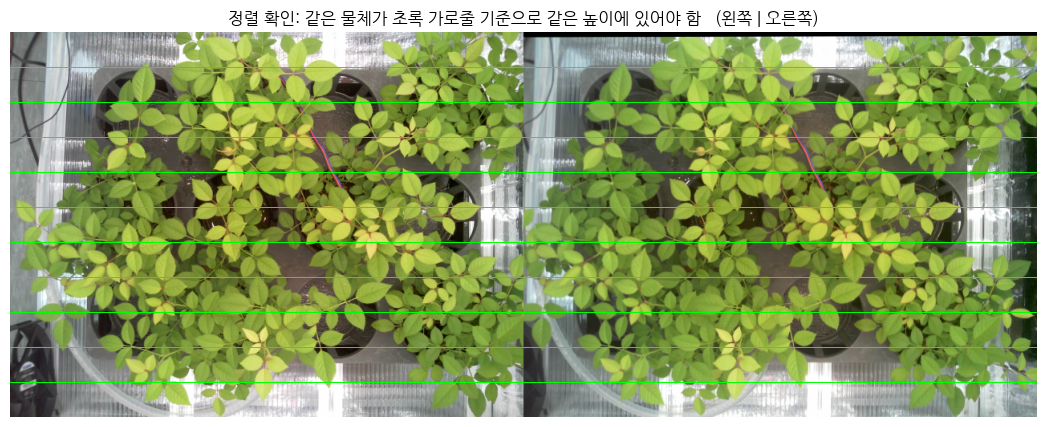

In [4]:
#@title 3. 사진 불러오기 + 정렬(평행화)
def load(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)   # 스마트폰 사진의 회전(EXIF)도 반영됨
    if img is None:
        raise ValueError(f"이미지를 읽을 수 없습니다: {path} (jpg/png만 지원)")
    return img

L0, R0 = load(LEFT_PATH), load(RIGHT_PATH)
if L0.shape != R0.shape:
    print(f"⚠ 두 사진 크기가 다릅니다 {L0.shape[:2]} vs {R0.shape[:2]} → 오른쪽을 왼쪽 크기로 맞춤")
    R0 = cv2.resize(R0, (L0.shape[1], L0.shape[0]))

# --- 캘리브레이션 파일 확인 ---
calib = None
if RECTIFY_MODE == "auto" and CALIB_PATH:
    calib = np.load(CALIB_PATH)
    cw, ch = (int(v) for v in calib["size"])
    if (L0.shape[1], L0.shape[0]) != (cw, ch):
        # 가로세로 비율이 같으면 캘리브레이션 해상도로 맞춤 (같은 카메라로 찍은 큰 원본 사진 등)
        if abs(L0.shape[1] / L0.shape[0] - cw / ch) < 0.01:
            print(f"사진 크기 {L0.shape[1]}x{L0.shape[0]} → 캘리브레이션 크기 {cw}x{ch} 로 맞춤")
            L0 = cv2.resize(L0, (cw, ch), interpolation=cv2.INTER_AREA)
            R0 = cv2.resize(R0, (cw, ch), interpolation=cv2.INTER_AREA)
        else:
            print(f"⚠ 사진 비율 {L0.shape[1]}x{L0.shape[0]} ≠ 캘리브레이션 {cw}x{ch} → 캘리브레이션 사용 불가, y-align으로 진행")
            calib = None
mode = "calib" if calib is not None else ("none" if RECTIFY_MODE == "none" else "y-align")

def match_points(a, b, max_pts=4000):
    # SIFT 특징점 매칭 (Lowe ratio test)
    ga, gb = cv2.cvtColor(a, cv2.COLOR_BGR2GRAY), cv2.cvtColor(b, cv2.COLOR_BGR2GRAY)
    sift = cv2.SIFT_create(nfeatures=max_pts)
    ka, da = sift.detectAndCompute(ga, None)
    kb, db = sift.detectAndCompute(gb, None)
    if da is None or db is None or len(ka) < 10 or len(kb) < 10:
        return np.empty((0, 2)), np.empty((0, 2))
    knn = cv2.BFMatcher().knnMatch(da, db, k=2)
    good = [m for m, n in (p for p in knn if len(p) == 2) if m.distance < 0.75 * n.distance]
    pa = np.float32([ka[m.queryIdx].pt for m in good])
    pb = np.float32([kb[m.trainIdx].pt for m in good])
    return pa, pb

if mode == "calib":
    size = (cw, ch)
    m1 = cv2.initUndistortRectifyMap(calib["K1"], calib["D1"], calib["R1"], calib["P1"], size, cv2.CV_32FC1)
    m2 = cv2.initUndistortRectifyMap(calib["K2"], calib["D2"], calib["R2"], calib["P2"], size, cv2.CV_32FC1)
    L = cv2.remap(L0, *m1, cv2.INTER_LINEAR)
    R = cv2.remap(R0, *m2, cv2.INTER_LINEAR)
    Q = calib["Q"]
    print("✔ 캘리브레이션 파일로 왜곡 보정 + 평행화 완료 (정확 측정 모드)")
else:
    # 계산 해상도로 축소
    if RESIZE_WIDTH and L0.shape[1] > RESIZE_WIDTH:
        s = RESIZE_WIDTH / L0.shape[1]
        L = cv2.resize(L0, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        R = cv2.resize(R0, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    else:
        L, R = L0.copy(), R0.copy()
    h, w = L.shape[:2]

    if mode == "y-align":
        # 오른쪽 사진의 '세로 위치'만 보정 (y' = y + a + b*x + c*y)
        # 가로(x)는 건드리지 않으므로 '무한히 먼 곳 = 시차 0' 관계가 유지됨
        pl, pr = match_points(L, R)
        if len(pl) < 20:
            print(f"⚠ 매칭점이 {len(pl)}개뿐이라 세로 보정을 건너뜁니다 (무늬가 많은 장면으로 다시 찍어 보세요)")
        else:
            dy = pl[:, 1] - pr[:, 1]
            A = np.c_[np.ones(len(pr)), pr[:, 0], pr[:, 1]]
            keep = np.abs(dy - np.median(dy)) < 3 * (np.median(np.abs(dy - np.median(dy))) + 1)
            for _ in range(5):   # 이상치 제거하며 반복 최소제곱
                coef, *_ = np.linalg.lstsq(A[keep], dy[keep], rcond=None)
                res = dy - A @ coef
                keep = np.abs(res) < max(2.0, 3 * np.median(np.abs(res[keep])))
            xs, ys = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
            # yL = yR + a + b*x + c*yR  →  yR = (yL - a - b*x) / (1 + c)
            map_y = ((ys - coef[0] - coef[1] * xs) / (1 + coef[2])).astype(np.float32)
            R = cv2.remap(R, xs, map_y, cv2.INTER_LINEAR)
            print(f"✔ 세로 정렬 완료: 매칭점 {keep.sum()}/{len(pl)}개 사용, "
                  f"보정 전 세로 어긋남 중앙값 {np.median(np.abs(dy)):.1f}px → 보정 후 {np.median(np.abs(res[keep])):.2f}px")
    else:
        print("정렬 없이 진행 (두 사진이 이미 평행하다고 가정)")

    f_px = (w / 2) / np.tan(np.radians(HFOV_DEG) / 2)
    # Z = f*B/d 를 reprojectImageTo3D 형식의 Q 행렬로 구성
    Q = np.float32([[1, 0, 0, -w / 2],
                    [0, 1, 0, -h / 2],
                    [0, 0, 0, f_px],
                    [0, 0, 1 / BASELINE_MM, 0]])
    print(f"근사 측정 모드: 초점거리 ≈ {f_px:.0f}px (화각 {HFOV_DEG}°), 카메라 간격 {BASELINE_MM}mm")

# 정렬 확인: 같은 물체가 같은 가로줄 위에 있으면 OK
pair = np.hstack([L, R])
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(cv2.cvtColor(pair, cv2.COLOR_BGR2RGB))
for y in np.linspace(0, L.shape[0], 12)[1:-1]:
    ax.axhline(y, color="lime", lw=0.7)
ax.set_title("정렬 확인: 같은 물체가 초록 가로줄 기준으로 같은 높이에 있어야 함   (왼쪽 | 오른쪽)")
ax.axis("off"); plt.show()

In [5]:
#@title 4. 시차(disparity) 계산
gl = cv2.cvtColor(L, cv2.COLOR_BGR2GRAY)
gr = cv2.cvtColor(R, cv2.COLOR_BGR2GRAY)
h, w = gl.shape

# 매칭점으로 실제 시차 범위를 측정해서 SGBM 탐색 범위를 자동 설정
pl, pr = match_points(L, R)
d_pts = pl[:, 0] - pr[:, 0] if len(pl) else np.array([])
d_pts = d_pts[np.abs(pl[:, 1] - pr[:, 1]) < 2] if len(pl) else d_pts
if len(d_pts) >= 10:
    if np.median(d_pts) < 0:
        print("⚠ 시차가 음수입니다 → 왼쪽/오른쪽 사진이 바뀐 것 같아 자동으로 교체합니다")
        L, R, gl, gr = R, L, gr, gl
        d_pts = -d_pts
    lo, hi = np.percentile(d_pts, [1, 99.5])
    min_disp = int(max(0, np.floor(lo) - 8))
    scene_min_d = lo                                # 장면에서 가장 먼 곳의 시차
    # 매칭점이 없는 더 가까운 물체도 잡도록 위쪽은 넉넉하게 (x1.5 + 16px)
    num_disp = int(np.ceil((hi * 1.5 + 16 - min_disp) / 16) * 16)
else:
    print("⚠ 매칭점이 부족해 기본 탐색 범위를 사용합니다")
    min_disp, num_disp = 0, 128
    scene_min_d = 0
num_disp = int(min(max(num_disp, 16), (w - min_disp) // 16 * 16))
print(f"시차 탐색 범위: {min_disp} ~ {min_disp + num_disp} px")

bs = BLOCK_SIZE
sgbm = cv2.StereoSGBM_create(
    minDisparity=min_disp, numDisparities=num_disp, blockSize=bs,
    P1=8 * 3 * bs ** 2, P2=32 * 3 * bs ** 2, disp12MaxDiff=1,
    uniquenessRatio=10, speckleWindowSize=100, speckleRange=2,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
# 왼쪽 가장자리도 계산되도록, 탐색 범위만큼 왼쪽에 검은 여백을 붙여 계산한 뒤 잘라냄
# (여백이 없으면 OpenCV가 왼쪽 min_disp + num_disp 픽셀을 통째로 '측정 불가'로 처리)
PAD = min_disp + num_disp
glp = cv2.copyMakeBorder(gl, 0, 0, PAD, 0, cv2.BORDER_CONSTANT, value=0)
grp = cv2.copyMakeBorder(gr, 0, 0, PAD, 0, cv2.BORDER_CONSTANT, value=0)
raw = sgbm.compute(glp, grp)

# opencv-contrib가 있으면 WLS 필터로 빈 곳을 메우고 경계를 다듬음
if hasattr(cv2, "ximgproc"):
    right_m = cv2.ximgproc.createRightMatcher(sgbm)
    wls = cv2.ximgproc.createDisparityWLSFilter(sgbm)
    wls.setLambda(8000); wls.setSigmaColor(1.2)
    raw = wls.filter(raw, glp, disparity_map_right=right_m.compute(grp, glp))
    print("✔ WLS 필터 적용")
raw = raw[:, PAD:]                                   # 여백 잘라내기
disp = raw.astype(np.float32) / 16.0
valid_disp = disp > max(min_disp, 0.5)
# 짝이 되는 점이 오른쪽 사진 밖에 있으면(물리적으로 오른쪽 카메라에 안 보이는 영역) 제외
valid_disp &= (np.arange(w)[None, :] - disp) >= 0
# 가장 먼 배경보다도 왼쪽에 있는 열은 어떤 물체도 오른쪽 사진에 보일 수 없음 → 제외
valid_disp[:, :int(np.ceil(scene_min_d))] = False
print(f"유효 픽셀 비율: {valid_disp.mean() * 100:.0f}%")
cols = np.where(valid_disp.any(axis=0))[0]
if len(cols):
    print(f"측정 가능한 가로 범위: {cols[0]} ~ {cols[-1]} px (왼쪽 {cols[0]}px는 오른쪽 카메라에 안 보이는 영역)")

시차 탐색 범위: 21 ~ 101 px
✔ WLS 필터 적용
유효 픽셀 비율: 95%
측정 가능한 가로 범위: 30 ~ 639 px (왼쪽 30px는 오른쪽 카메라에 안 보이는 영역)


In [6]:
#@title 5. 거리 계산
# 시차 보정: 실제 시차 = 측정 시차 + DISP_OFFSET_PX
disp_corr = np.where(valid_disp, disp + DISP_OFFSET_PX, 0).astype(np.float32)
pts3d = cv2.reprojectImageTo3D(disp_corr, Q)
Z_cm = pts3d[:, :, 2] / 10.0                      # mm → cm
valid = valid_disp & np.isfinite(Z_cm) & (Z_cm > 0) & (Z_cm < MAX_DIST_CM)
depth_cm = np.where(valid, Z_cm, np.nan)

def distance_at(x, y, roi=7):
    # (x, y) 주변 roi x roi 영역의 유효 거리 중앙값 (cm)
    r = roi // 2
    patch = depth_cm[max(0, y - r):y + r + 1, max(0, x - r):x + r + 1]
    vals = patch[np.isfinite(patch)]
    return float(np.median(vals)) if vals.size >= max(1, patch.size // 4) else None

if not valid.any():
    raise SystemExit("유효한 거리값이 없습니다. 3번 정렬 그림과 설정값(BASELINE_MM, HFOV_DEG)을 확인하세요.")
d_c = distance_at(w // 2, h // 2, roi=21)
print(f"측정된 거리 범위: {np.nanmin(depth_cm):.1f} ~ {np.nanmax(depth_cm):.1f} cm")
print(f"화면 중앙 거리: {d_c:.1f} cm" if d_c else "화면 중앙: 측정 불가")

측정된 거리 범위: 34.1 ~ 78.5 cm
화면 중앙 거리: 46.2 cm


In [7]:
#@title 6. 결과 보기
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(cv2.cvtColor(L, cv2.COLOR_BGR2RGB)); axs[0].set_title("왼쪽 (정렬 후)")
dv = np.where(valid_disp, disp, np.nan)
im1 = axs[1].imshow(dv, cmap="jet"); axs[1].set_title("시차 (px) — 빨강 = 가까움")
plt.colorbar(im1, ax=axs[1], fraction=0.046)
im2 = axs[2].imshow(depth_cm, cmap="turbo_r"); axs[2].set_title("거리 (cm) — 빨강 = 가까움")
plt.colorbar(im2, ax=axs[2], fraction=0.046)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

# 마우스를 올리면 거리(cm)가 표시되는 인터랙티브 그림
import plotly.graph_objects as go
step = max(1, w // 400)                            # 너무 크면 브라우저가 느려지므로 축소
rgb = cv2.cvtColor(L, cv2.COLOR_BGR2RGB)[::step, ::step]
dsub = depth_cm[::step, ::step]
fig = go.Figure()
fig.add_trace(go.Image(z=rgb, x0=0, y0=0, dx=step, dy=step, hoverinfo="skip"))
fig.add_trace(go.Heatmap(z=dsub, x=np.arange(0, w, step), y=np.arange(0, h, step),
                         colorscale="Turbo", reversescale=True, opacity=0.35,
                         colorbar=dict(title="cm"),
                         hovertemplate="x=%{x}, y=%{y}<br>거리: %{z:.1f} cm<extra></extra>"))
fig.update_layout(title="마우스를 올리면 거리 표시 (색이 없는 곳 = 측정 불가)",
                  width=900, height=int(900 * h / w) + 60, margin=dict(l=0, r=0, t=40, b=0))
fig.update_yaxes(autorange="reversed", scaleanchor="x", showticklabels=False)
fig.update_xaxes(showticklabels=False)
fig.show()

Output hidden; open in https://colab.research.google.com to view.

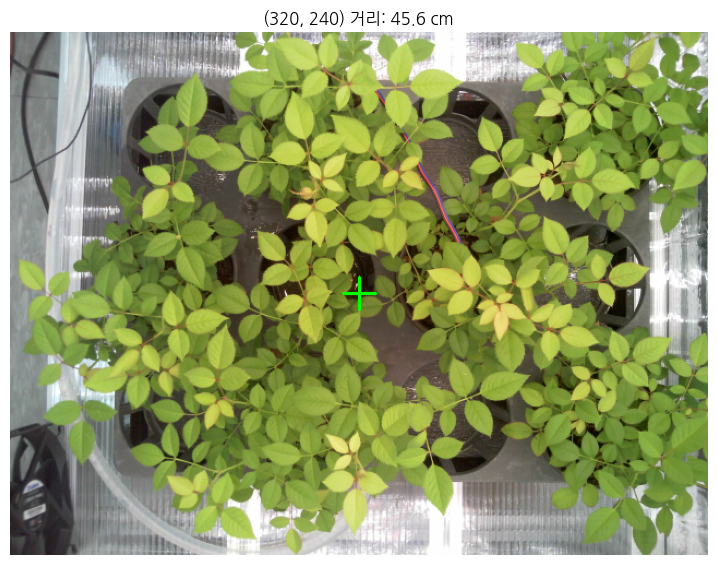

In [8]:
#@title 7. 원하는 지점 거리 측정 { run: "auto" }
#@markdown 위 그림에서 마우스로 확인한 x, y 좌표를 입력하세요
POINT_X = 320  #@param {type:"integer"}
POINT_Y = 240  #@param {type:"integer"}
ROI = 9        #@param {type:"slider", min:1, max:31, step:2}

x, y = int(np.clip(POINT_X, 0, w - 1)), int(np.clip(POINT_Y, 0, h - 1))
d = distance_at(x, y, ROI)
view = cv2.cvtColor(L, cv2.COLOR_BGR2RGB).copy()
cv2.drawMarker(view, (x, y), (0, 255, 0), cv2.MARKER_CROSS, 30, 2)
plt.figure(figsize=(9, 7)); plt.imshow(view); plt.axis("off")
plt.title(f"({x}, {y}) 거리: {d:.1f} cm" if d else f"({x}, {y}) 측정 불가 — 무늬가 있는 곳을 골라 보세요")
plt.show()

In [9]:
#@title 8. (선택) 결과 다운로드
np.save("depth_cm.npy", depth_cm)
vis = cv2.applyColorMap(cv2.normalize(np.nan_to_num(-depth_cm, nan=np.nanmin(-depth_cm)), None, 0, 255,
                                      cv2.NORM_MINMAX).astype(np.uint8), cv2.COLORMAP_TURBO)
cv2.imwrite("depth_color.png", vis)
files.download("depth_cm.npy"); files.download("depth_color.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 결과가 이상할 때

| 증상 | 해결 |
|---|---|
| 3번 그림에서 같은 물체 높이가 다름 | 카메라를 같은 높이·방향으로 다시 촬영, 또는 캘리브레이션 파일 사용 |
| 시차 맵이 대부분 비어 있음 | 무늬가 많은 장면, 밝은 곳에서 촬영. `BLOCK_SIZE` 7~9로 키우기 |
| 거리가 일정 비율로 틀림 | `HFOV_DEG`, `BASELINE_MM` 확인. 실제 거리를 아는 물체로 화각 값을 조정 |
| 가까운 물체가 측정 안 됨 | 너무 가까움 (간격 6cm면 약 30cm 이상 권장) |
| 좌우가 바뀜 | 4번 셀이 자동으로 감지해 교체함 |